In [1]:
%pip install ultralytics


  Attempting uninstall: setuptools
    Found existing installation: setuptools 57.4.0
    Uninstalling setuptools-57.4.0:
      Successfully uninstalled setuptools-57.4.0


You should consider upgrading via the 'c:\Users\shive\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


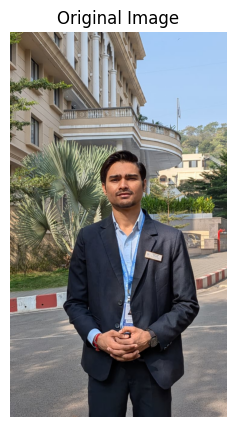

Image loaded successfully.


In [2]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

CURRENT_DIR = Path.cwd()
PROJECT_DIR = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR

IMAGE_PATH = PROJECT_DIR / "data" / "images" / "original.jpeg"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "task3_object_detection"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

image_bgr = cv2.imread(str(IMAGE_PATH))

if image_bgr is None:
    raise FileNotFoundError(f"Image not found: {IMAGE_PATH.resolve()}")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(7, 5))
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

print("Image loaded successfully.")

In [8]:
import cv2
from pathlib import Path

cascade_path = Path(cv2.data.haarcascades) / "haarcascade_frontalface_default.xml"

print("Cascade folder:", cv2.data.haarcascades)
print("File exists:", cascade_path.exists())
print("File path:", cascade_path)

Cascade folder: c:\Users\shive\AppData\Local\Programs\Python\Python310\lib\site-packages\cv2\data\
File exists: False
File path: c:\Users\shive\AppData\Local\Programs\Python\Python310\lib\site-packages\cv2\data\haarcascade_frontalface_default.xml


In [10]:
from urllib.request import urlretrieve
from pathlib import Path

CASCADE_DIR = PROJECT_DIR / "data" / "haarcascades"
CASCADE_DIR.mkdir(parents=True, exist_ok=True)

CASCADE_PATH = CASCADE_DIR / "haarcascade_frontalface_default.xml"

url = (
    "https://raw.githubusercontent.com/opencv/opencv/master/"
    "data/haarcascades/haarcascade_frontalface_default.xml"
)

urlretrieve(url, str(CASCADE_PATH))

print("Downloaded:", CASCADE_PATH)
print("File exists:", CASCADE_PATH.exists())
print("File size:", CASCADE_PATH.stat().st_size, "bytes")

Downloaded: d:\Projects\CV\data\haarcascades\haarcascade_frontalface_default.xml
File exists: True
File size: 930127 bytes


Faces detected: 3


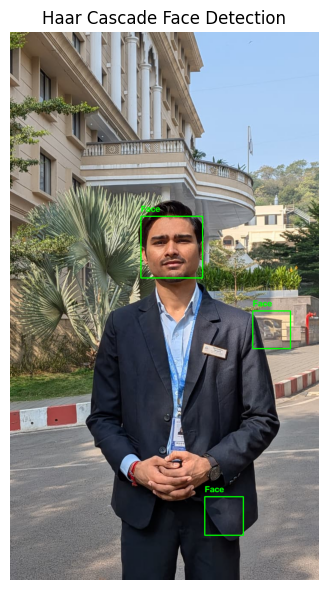

In [11]:
face_cascade = cv2.CascadeClassifier(str(CASCADE_PATH))

if face_cascade.empty():
    raise RuntimeError("The downloaded Haar Cascade file could not be loaded.")

gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

haar_result = image_rgb.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(haar_result, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.putText(
        haar_result, "Face", (x, max(y - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2
    )

print("Faces detected:", len(faces))

plt.figure(figsize=(8, 6))
plt.imshow(haar_result)
plt.title("Haar Cascade Face Detection")
plt.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_haar_face_detection.png", dpi=150)
plt.show()

Objects detected: 1
person: 0.95


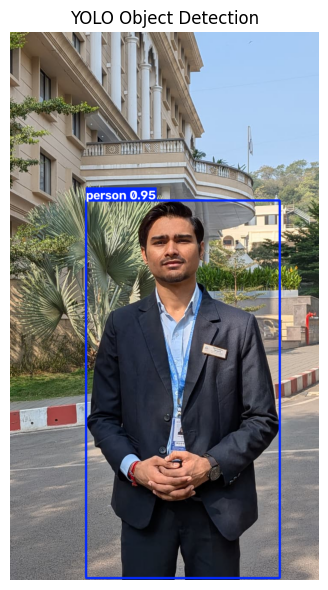

In [5]:
model = YOLO("yolo11n.pt")

results = model.predict(
    source=str(IMAGE_PATH),
    conf=0.25,
    verbose=False
)

result = results[0]
yolo_result = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)

print("Objects detected:", len(result.boxes))

for box in result.boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    print(f"{model.names[class_id]}: {confidence:.2f}")

plt.figure(figsize=(8, 6))
plt.imshow(yolo_result)
plt.title("YOLO Object Detection")
plt.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_yolo_detection.png", dpi=150)
plt.show()

## Observations

- Haar Cascade detected  faces.
- YOLO detected one objects.
- Haar Cascade was used for face detection, while YOLO detected objects from its trained classes.
- The methods were compared based on the number of detections and the correctness of their bounding boxes.
- Any missed or incorrect detections observed:.